# Exercise 5. Neural Network Architecture

The purpose of this exercise is understand and define the neural network architectures and activation function for different kind of prediction or classification problem.

In each NN you have to define:
1. Input layer: Number of nodes and activation function
2. Hidden layers: Activation function 
3. Output layer: Number of nodes  and activation function

You __don't need to download and train your NN__, just contruct and compile NN.

## Regression 

Used dataset is [Boston House pricing](https://www.kaggle.com/vikrishnan/boston-house-prices)

Each record in the database describes a Boston suburb or town. The data was drawn from the Boston Standard Metropolitan Statistical Area (SMSA) in 1970. The attributes are deﬁned as follows (taken from the UCI Machine Learning Repository): 
1. CRIM: per capita crime rate by town
2. ZN: proportion of residential land zoned for lots over 25,000 sq.ft.
3. INDUS: proportion of non-retail business acres per town
4. CHAS: Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
5. NOX: nitric oxides concentration (parts per 10 million)
6. RM: average number of rooms per dwelling
7. AGE: proportion of owner-occupied units built prior to 1940
8. DIS: weighted distances to ﬁve Boston employment centers
9. RAD: index of accessibility to radial highways
10. TAX: full-value property-tax rate per 10,000 dollars
11. PTRATIO: pupil-teacher ratio by town 
12. B: 1000(Bk−0.63)2 where Bk is the proportion of blacks by town 
13. LSTAT:  lower status of the population
14. MEDV: Median value of owner-occupied homes in dollars 1000s

In [1]:
import tensorflow as tf
import pandas as pd 
tf.keras.backend.set_floatx('float64')
from tensorflow.keras import layers
from tensorflow import keras

In [2]:
# Define NN using Keras Functional API
# Input layer with suitable amount of nodes
# 1. hidden layer: 13
# Output layer: number of nodes, activation function and loss
# Implementation comes to this cell

# Input layer: 13 nodes (one per input feature), no activation function
inputs = tf.keras.Input(shape=(13,))

# hidden layer: 13 nodes, ReLU activation
hidden = tf.keras.layers.Dense(13, activation='relu')(inputs)

# Output layer: 1 node (the house price), linear activation (for regression)
outputs = tf.keras.layers.Dense(1, activation='linear')(hidden)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Compile model with following options: 
# Define loss function and use adam optimization algorithm 
# loss function is mean squared error for regression problems
model.compile(loss='mean_squared_error', optimizer='adam')

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 13)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 13)             │           182 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            14 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 196 (1.53 KB)

 Trainable params: 196 (1.53 KB)

 Non-trainable params: 0 (0.00 B)

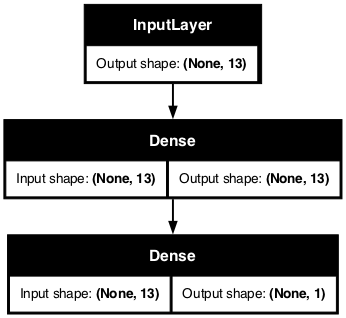

In [3]:
tf.keras.utils.plot_model(model,dpi=70,show_shapes=True)

## Binary Classification

__Short description of dataset:__ [Sonar dataset](https://archive.ics.uci.edu/ml/datasets/Connectionist+Bench+(Sonar,+Mines+vs.+Rocks))

This is a dataset that describes sonar chirp returns bouncing off different services. The 60 input variables are the strength of the returns at different angles. It is a binary classification problem that requires a model to differentiate rocks from metal cylinders.

All of the variables are continuous and generally in the range of 0 to 1. The output variable is a string “M” for mine and “R” for rock, which will need to be converted to integers 1 and 0.

In [4]:
# Define NN using Keras Functional API
# Input layer with suitable amount of nodes
# 1. hidden layer: 30
# Output layer: number of nodes, activation function and loss
# Implementation comes to this cell

# Input layer: 60 nodes (one per input feature), no activation function
inputs = tf.keras.Input(shape=(60,))

# hidden layer: 30 nodes, ReLU activation
hidden = tf.keras.layers.Dense(30, activation='relu')(inputs)

# Output layer: 1 node, sigmoid activation (for binary classification)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(hidden)

model = tf.keras.Model(inputs=inputs, outputs=outputs)


# Compile model with following options: 
# Define loss function and use adam optimization algorithm 
# loss function is binary crossentropy for binary classification
model.compile(loss='binary_crossentropy', optimizer='adam')

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 60)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 30)             │         1,830 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,861 (14.54 KB)

 Trainable params: 1,861 (14.54 KB)

 Non-trainable params: 0 (0.00 B)

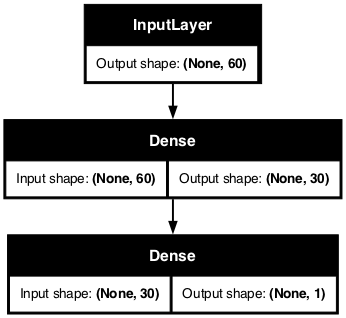

In [5]:
tf.keras.utils.plot_model(model,dpi=70,show_shapes=True)

## Multiclass Classification

[Wines dataset](https://archive.ics.uci.edu/ml/datasets/Wine%2BQuality) which contains 12 attributes, 11 wine features and 1 rate (1-10) at the end.

Features:
- Fixed acidity
- Volatile acidity
- Citric acid
- Residual sugar
- Chlorides
- Free sulfur dioxide
- Total sulfur dioxide
- Density
- pH
- Sulfates
- Alcohol

Quality (1-10) is an class as follows
1-3: Bad
4-6: Good
7-10: Excellend


In [6]:
# Define NN using Keras Functional API
# Input layer with suitable amount of nodes
# 1. hidden layer: 30
# 2. hidden layer: 40
# 3. hidden layer: 20
# Output layer: number of nodes, activation function and loss
# Implementation comes to this cell

# Input layer: 11 nodes (one per wine feature), no activation function
inputs = tf.keras.Input(shape=(11,))

# Hidden layers: 30, 40 and 20 nodes, ReLU activation
hidden1 = tf.keras.layers.Dense(30, activation='relu')(inputs)
hidden2 = tf.keras.layers.Dense(40, activation='relu')(hidden1)
hidden3 = tf.keras.layers.Dense(20, activation='relu')(hidden2)

# Output layer: 3 nodes (Bad, Good, Excellent), softmax activation (for multi-class classification)
outputs = tf.keras.layers.Dense(3, activation='softmax')(hidden3)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Compile model with following options: 
# Define loss function and use adam optimization algorithm
# loss function is categorical crossentropy for multi-class classification
model.compile(loss='categorical_crossentropy', optimizer='adam')

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 11)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 30)             │           360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 40)             │         1,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 20)             │           820 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,483 (19.40 KB)

 Trainable params: 2,483 (19.40 KB)

 Non-trainable params: 0 (0.00 B)

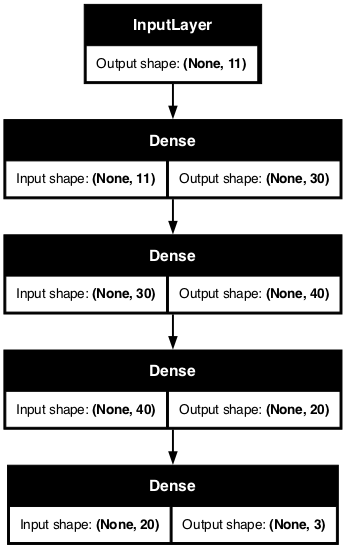

In [7]:
tf.keras.utils.plot_model(model,dpi=70,show_shapes=True)

## Multilabel Classification

Imagenary dataset will have 1,000 samples with 10 input features. The dataset will have three class label outputs for each sample and each class will have one or two values (0 or 1, e.g. present or not present).



In [8]:
# Define NN using Keras Functional API
# Input layer with suitable amount of nodes
# 1. hidden layer: 20
# 2. hidden layer: 20
# Output layer: number of nodes, activation function and loss
# Implementation comes to this cell

# Input layer: 10 nodes (one per input feature), no activation function
inputs = tf.keras.Input(shape=(10,))


# Hidden layers: 20 and 20 nodes, ReLU activation
hidden1 = tf.keras.layers.Dense(20, activation='relu')(inputs)
hidden2 = tf.keras.layers.Dense(20, activation='relu')(hidden1)

# Output layer: 3 nodes (one per label), sigmoid activation (for multi-label classification)
outputs = tf.keras.layers.Dense(3, activation='sigmoid')(hidden2)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Compile model with following options: 
# Define loss function and use adam optimization algorithm 
# loss function is binary crossentropy for multi-label classification
model.compile(loss='binary_crossentropy', optimizer='adam')

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 703 (5.49 KB)

 Trainable params: 703 (5.49 KB)

 Non-trainable params: 0 (0.00 B)

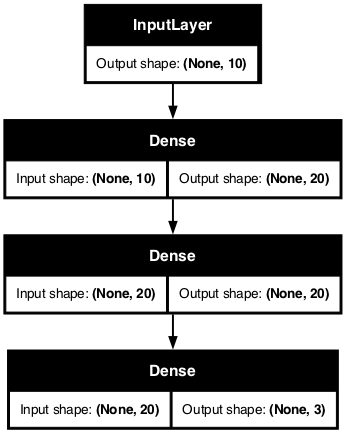

In [9]:
tf.keras.utils.plot_model(model,dpi=70,show_shapes=True)

__Conclusion__

__NOTE: Conclusion is one evaluation criterion for the exercise, so pay attention to writing them__

#### Write conclusion:

**Do you understand the purpose of the activation function and when to use a specific one?**

Yes, I understand the main idea. An activation function decides what a node passes on to the
next layer. In the hidden layers, I used ReLU. It lets the network learn more complex patterns.
Without an activation function, the layers would act like one simple linear model. The input
layer has no activation function, because it only passes the data into the network.

The activation function in the output layer depends on the type of problem:

| Problem | Output activation |
|---|---|
| Regression (predict a number) | linear |
| Binary classification (two classes) | sigmoid |
| Multiclass (one class out of several) | softmax |
| Multilabel (several yes/no labels) | sigmoid |

- **Linear** lets the output be any number, which is needed for a price.
- **Sigmoid** gives a value between 0 and 1, which can be read as a probability.
- **Softmax** gives probabilities that add up to 1, so it works when a sample belongs to
  exactly one class.
- In multilabel, each label is its own yes/no question, so every output gets its own sigmoid.

**What you learn in this exercise?**

- The number of input nodes is the number of features in the data.
- The number of output nodes and the output activation depend on the type of problem.
- The loss function has to match the output layer, for example sigmoid goes with binary
  crossentropy and softmax goes with categorical crossentropy.
- The difference between multiclass and multilabel. In multiclass only one class is right and
  in multilabel several labels can be present at the same time.
- With model.summary() I can check the layers and the number of parameters, and plot_model
  shows the structure as a picture.

**Did you have difficulties in the exercise?**

Yes, initially I had trouble understanding the difference between multiclass and multilabel classification, because they look similar. I also had to install extra software (pydot and Graphviz) before plot_model worked.

**AI Usage**

I used AI as an assistant in this exercise as well. It helped me to understand the concepts I did not understand, such as the activation functions,the loss functions, and the difference between multiclass and multilabel classification. It also helped me install Graphviz so that plot_model works, and it helped me draft the conclusion. I ran the notebook myself and checked that the layer sizes and the parameter counts in model.summary() match the exercise.